# Supervised Learning & Model Engineering Project - Census Income

### CAILLAUD Jérémy - RAHJI Yanis - VAN ... Hugo

## <span style="color: red;">Import</span>

### <span style="color: green;">Import des packages</span>

In [99]:
from sklearn.datasets import fetch_openml
import pandas as pd
import numpy as np
import missingno as msno
import matplotlib.pyplot as plt

### <span style="color: green;">Import de la Dataset</span>

In [100]:
# Option 1 -- Adult / Census Income
adult = fetch_openml(name="adult", version=2, as_frame=True)
X, y = adult.data, adult.target

## <span style="color: red;">1 - Analyse exploratoire (EDA) et cadrage du problème</span> 

### <span style="color: green;">Analyse de la DataSet</span> 

#### Aperçu

In [101]:
df = adult.frame

In [102]:
df.shape

(48842, 15)

Le dataset contient 48 842 lignes, une par personne, et 15 colonnes : 14 variables descriptives et la cible `class`.

In [103]:
df.columns

Index(['age', 'workclass', 'fnlwgt', 'education', 'education-num',
       'marital-status', 'occupation', 'relationship', 'race', 'sex',
       'capital-gain', 'capital-loss', 'hours-per-week', 'native-country',
       'class'],
      dtype='str')

In [104]:
df.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,class
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,NaN,103497,Some-college,10,Never-married,NaN,Own-child,White,Female,0,0,30,United-States,<=50K


Chaque ligne décrit une personne. On voit dès les premières lignes des valeurs manquantes (`NaN`) dans `workclass` et `occupation`.

In [105]:
df.tail()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,class
48837,27,Private,257302,Assoc-acdm,12,Married-civ-spouse,Tech-support,Wife,White,Female,0,0,38,United-States,<=50K
48838,40,Private,154374,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,40,United-States,>50K
48839,58,Private,151910,HS-grad,9,Widowed,Adm-clerical,Unmarried,White,Female,0,0,40,United-States,<=50K
48840,22,Private,201490,HS-grad,9,Never-married,Adm-clerical,Own-child,White,Male,0,0,20,United-States,<=50K
48841,52,Self-emp-inc,287927,HS-grad,9,Married-civ-spouse,Exec-managerial,Wife,White,Female,15024,0,40,United-States,>50K


In [106]:
df.sample(5)

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,class
38938,51,Private,138852,HS-grad,9,Married-civ-spouse,Tech-support,Husband,White,Male,0,0,40,United-States,<=50K
18665,19,Private,172893,Some-college,10,Never-married,Exec-managerial,Own-child,White,Female,0,0,30,United-States,<=50K
18125,53,Private,121618,7th-8th,4,Never-married,Transport-moving,Not-in-family,Amer-Indian-Eskimo,Male,0,0,40,United-States,<=50K
10877,37,Private,174329,Some-college,10,Never-married,Other-service,Own-child,White,Male,0,0,20,United-States,<=50K
23322,35,Private,141896,12th,8,Married-civ-spouse,Craft-repair,Husband,White,Male,0,0,40,United-States,<=50K


#### Doublons

In [108]:
df[df.duplicated(keep=False)].sort_values(list(df.columns))

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,class
4152,17,Private,153021,12th,8,Never-married,Sales,Own-child,White,Female,0,0,20,United-States,<=50K
40948,17,Private,153021,12th,8,Never-married,Sales,Own-child,White,Female,0,0,20,United-States,<=50K
3900,18,Self-emp-inc,378036,12th,8,Never-married,Farming-fishing,Own-child,White,Male,0,0,10,United-States,<=50K
15960,18,Self-emp-inc,378036,12th,8,Never-married,Farming-fishing,Own-child,White,Male,0,0,10,United-States,<=50K
33954,19,Private,97261,HS-grad,9,Never-married,Farming-fishing,Not-in-family,White,Male,0,0,40,United-States,<=50K
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
38156,49,Private,31267,7th-8th,4,Married-civ-spouse,Craft-repair,Husband,White,Male,0,0,40,United-States,<=50K
23334,49,Self-emp-not-inc,43479,Some-college,10,Married-civ-spouse,Craft-repair,Husband,White,Male,0,0,40,United-States,<=50K
38775,49,Self-emp-not-inc,43479,Some-college,10,Married-civ-spouse,Craft-repair,Husband,White,Male,0,0,40,United-States,<=50K
18584,90,Private,52386,Some-college,10,Never-married,Other-service,Not-in-family,Asian-Pac-Islander,Male,0,0,35,United-States,<=50K


Ce tableau liste les 101 lignes qui existent en plusieurs exemplaires : 52 d'entre elles sont des copies en trop, soit 0,1 % du dataset.

Les lignes en double sont identiques jusqu'au poids `fnlwgt`, qui prend pourtant des dizaines de milliers de valeurs différentes : une coïncidence est peu probable.

In [109]:
# 52 lignes strictement identiques sur les 15 variables, y compris le poids d’échantillonnage. 
# En l’absence d’identifiant, nous les considérons comme des doublons de saisie et les supprimons, 
# pour éviter qu’une même observation figure à la fois dans le jeu d’entraînement et dans le jeu de test.

df = df.drop_duplicates().reset_index(drop=True)
df.shape

(48790, 15)

In [118]:
df.duplicated().sum()

np.int64(0)

#### Types et valeurs manquantes

In [110]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 48790 entries, 0 to 48789
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype   
---  ------          --------------  -----   
 0   age             48790 non-null  int64   
 1   workclass       45995 non-null  category
 2   fnlwgt          48790 non-null  int64   
 3   education       48790 non-null  category
 4   education-num   48790 non-null  int64   
 5   marital-status  48790 non-null  category
 6   occupation      45985 non-null  category
 7   relationship    48790 non-null  category
 8   race            48790 non-null  category
 9   sex             48790 non-null  category
 10  capital-gain    48790 non-null  int64   
 11  capital-loss    48790 non-null  int64   
 12  hours-per-week  48790 non-null  int64   
 13  native-country  47934 non-null  category
 14  class           48790 non-null  category
dtypes: category(9), int64(6)
memory usage: 2.7 MB


Les types sont corrects : 6 variables numériques (`int64`) et 9 catégorielles (`category`). Trois colonnes ont des valeurs manquantes : `workclass`, `occupation` et `native-country`.

In [114]:
df.nunique(dropna=False) == 1

age               False
workclass         False
fnlwgt            False
education         False
education-num     False
marital-status    False
occupation        False
relationship      False
race              False
sex               False
capital-gain      False
capital-loss      False
hours-per-week    False
native-country    False
class             False
dtype: bool

Aucune colonne n'est constante : toutes les variables peuvent apporter de l'information.

<Axes: >

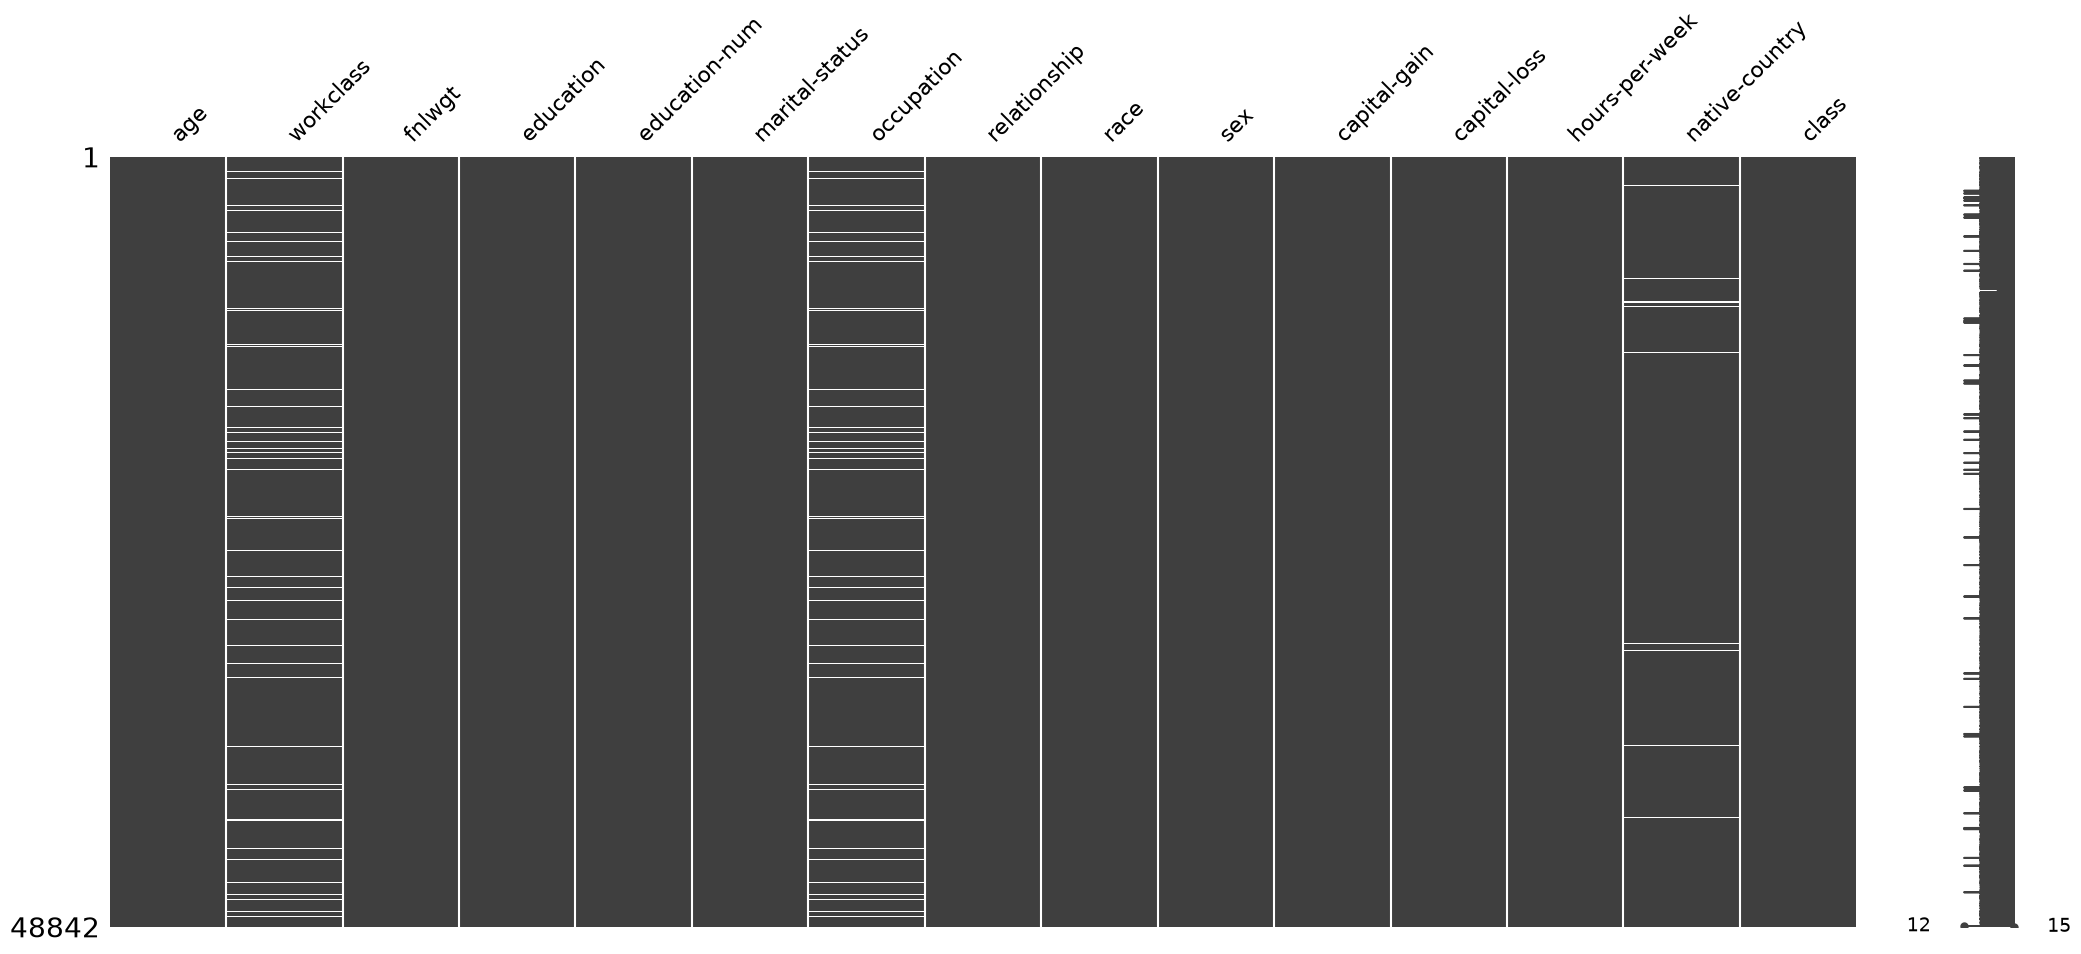

In [107]:
msno.matrix(df)

Les traits blancs sont les valeurs manquantes : elles ne concernent que `workclass`, `occupation` et `native-country`. Celles de `workclass` et `occupation` tombent sur les mêmes lignes.

In [116]:
df[["workclass", "occupation", "native-country"]].isna().value_counts()

workclass  occupation  native-country
False      False       False             45175
True       True        False              2749
False      False       True                810
True       True        True                 46
False      True        False                10
Name: count, dtype: int64

`workclass` et `occupation` manquent ensemble sur 2 795 lignes (2 749 + 46), alors que `native-country` manque le plus souvent seule (810 lignes). Dans 10 lignes seule `occupation` manque : ce sont les personnes `Never-worked`.

In [117]:
df.isna().mean()

age               0.000000
workclass         0.057286
fnlwgt            0.000000
education         0.000000
education-num     0.000000
marital-status    0.000000
occupation        0.057491
relationship      0.000000
race              0.000000
sex               0.000000
capital-gain      0.000000
capital-loss      0.000000
hours-per-week    0.000000
native-country    0.017545
class             0.000000
dtype: float64

Les taux restent faibles : 5,7 % pour `workclass` et `occupation`, 1,8 % pour `native-country`. Aucune colonne n'est à écarter à cause des valeurs manquantes.

#### Variables numériques

In [111]:
df.describe()

,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week
count,48790.000000,4.879000e+04,48790.000000,48790.000000,48790.000000,48790.000000
mean,38.652798,1.896690e+05,10.078807,1080.217688,87.595573,40.425886
std,13.708493,1.056172e+05,2.570046,7455.905921,403.209129,12.392729
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.175550e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.781385e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.376062e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.490400e+06,16.000000,99999.000000,4356.000000,99.000000


L'âge va de 17 à 90 ans (médiane 37) et le temps de travail médian est de 40 h par semaine. `capital-gain` et `capital-loss` valent 0 pour au moins 75 % des personnes, et le maximum de `capital-gain` (99 999) est très éloigné du reste.

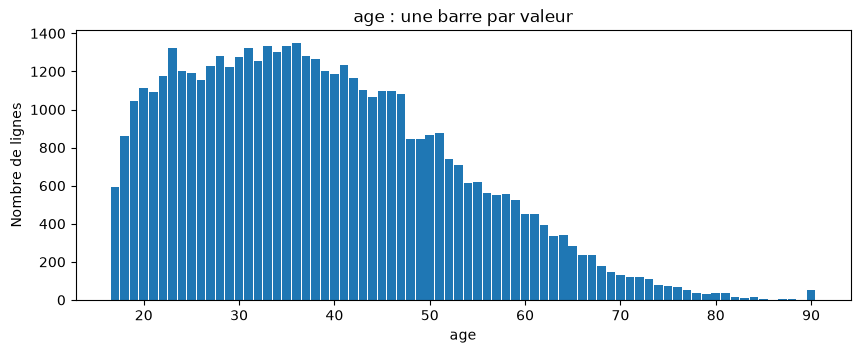

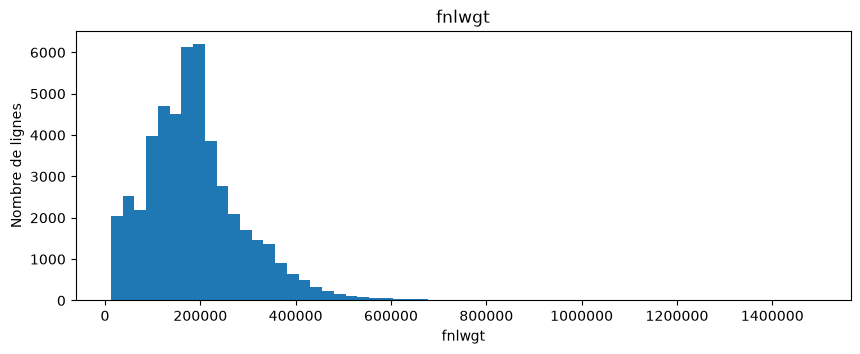

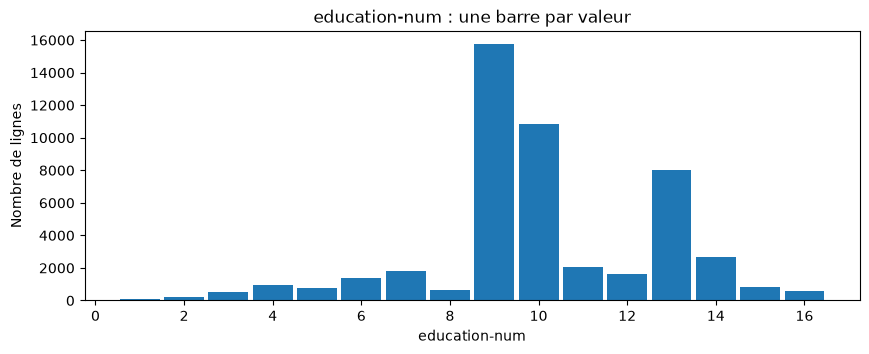

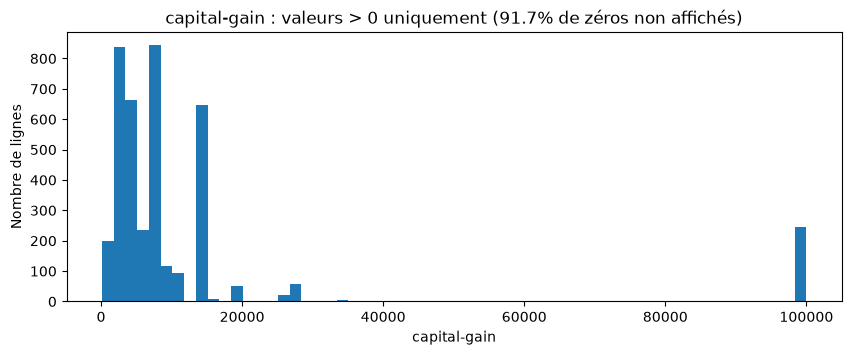

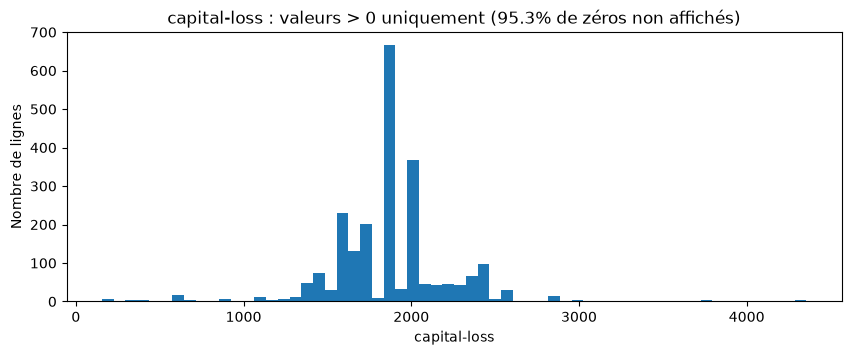

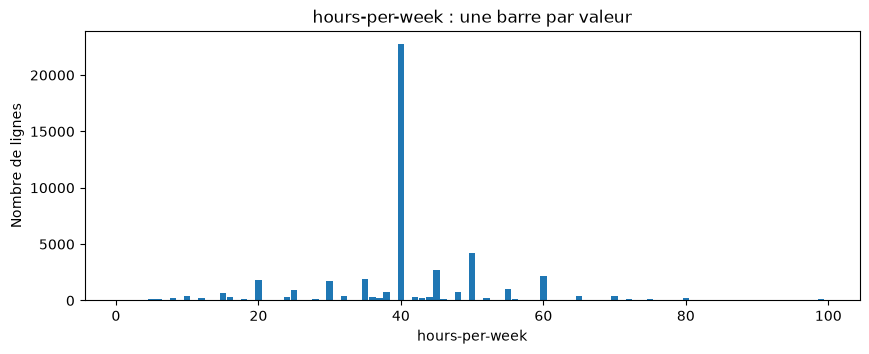

In [121]:
for col in df.select_dtypes("number"):
    s = df[col]
    part_zeros = (s == 0).mean()
    fig, ax = plt.subplots(figsize=(10, 3.5))

    if part_zeros > 0.5:
        # capital-gain, capital-loss : presque que des zéros, on trace le reste
        ax.hist(s[s > 0], bins=60)
        ax.set_title(f"{col} : valeurs > 0 uniquement ({part_zeros:.1%} de zéros non affichés)")
    elif s.nunique() <= 100:
        # age, education-num, hours-per-week : valeurs entières, une barre par valeur
        counts = s.value_counts().sort_index()
        ax.bar(counts.index, counts.values, width=0.9)
        ax.set_title(f"{col} : une barre par valeur")
    else:
        # fnlwgt : variable continue, histogramme classique
        ax.hist(s, bins=60)
        ax.ticklabel_format(style="plain", axis="x")
        ax.set_title(col)

    ax.set_xlabel(col)
    ax.set_ylabel("Nombre de lignes")
    plt.show()

`hours-per-week` a un pic très net à 40 h et `education-num` trois niveaux dominants (9, 10 et 13). Pour `capital-gain`, une barre isolée apparaît à 99 999, étudiée juste en dessous ; `age` montre aussi un petit regroupement à 90.

In [112]:
(df["capital-gain"] == 99999).sum()

np.int64(244)

Le 99 999 de capital-gain est un plafond de saisie

In [113]:
tranches = pd.cut(df["capital-gain"], [-1, 0, 5000, 10000, 41310, 99999])
(df["class"] == ">50K").groupby(tranches, observed=True).agg(["size", "mean"])

,size,mean
capital-gain,,
"(-1, 0]",44755,0.205340
"(0, 5000]",1584,0.178662
"(5000, 10000]",1317,0.829157
"(10000, 41310]",890,0.979775
"(41310, 99999]",244,1.000000


Le taux de `>50K` est d'environ 20 % sans gain en capital, puis monte à 83 % entre 5 000 et 10 000 et à 98 % au-delà. Les 244 personnes au plafond sont toutes en `>50K` : ces lignes sont informatives, on les garde.

#### Variables catégorielles

In [115]:
df.describe(include="category")

,workclass,education,marital-status,occupation,relationship,race,sex,native-country,class
count,45995,48790,48790,45985,48790,48790,48790,47934,48790
unique,8,16,7,14,6,5,2,41,2
top,Private,HS-grad,Married-civ-spouse,Prof-specialty,Husband,White,Male,United-States,<=50K
freq,33860,15770,22366,6165,19703,41714,32614,43792,37109


`native-country` a le plus de modalités (41), mais `United-States` représente 91 % des valeurs renseignées. La cible est déséquilibrée : 76 % des personnes sont en `<=50K`.

In [120]:
for col in df.select_dtypes("category"):
    display(df[col].value_counts(dropna=False))

workclass
Private             33860
Self-emp-not-inc     3861
Local-gov            3136
NaN                  2795
State-gov            1981
Self-emp-inc         1694
Federal-gov          1432
Without-pay            21
Never-worked           10
Name: count, dtype: int64

education
HS-grad         15770
Some-college    10863
Bachelors        8013
Masters          2656
Assoc-voc        2060
11th             1812
Assoc-acdm       1601
10th             1389
7th-8th           954
Prof-school       834
9th               756
12th              655
Doctorate         594
5th-6th           507
1st-4th           245
Preschool          81
Name: count, dtype: int64

marital-status
Married-civ-spouse       22366
Never-married            16082
Divorced                  6630
Separated                 1530
Widowed                   1518
Married-spouse-absent      627
Married-AF-spouse           37
Name: count, dtype: int64

occupation
Prof-specialty       6165
Craft-repair         6102
Exec-managerial      6082
Adm-clerical         5606
Sales                5501
Other-service        4919
Machine-op-inspct    3017
NaN                  2805
Transport-moving     2355
Handlers-cleaners    2071
Farming-fishing      1485
Tech-support         1445
Protective-serv       982
Priv-house-serv       240
Armed-Forces           15
Name: count, dtype: int64

relationship
Husband           19703
Not-in-family     12557
Own-child          7569
Unmarried          5124
Wife               2331
Other-relative     1506
Name: count, dtype: int64

race
White                 41714
Black                  4683
Asian-Pac-Islander     1517
Amer-Indian-Eskimo      470
Other                   406
Name: count, dtype: int64

sex
Male      32614
Female    16176
Name: count, dtype: int64

native-country
United-States                 43792
Mexico                          943
NaN                             856
Philippines                     294
Germany                         206
Puerto-Rico                     184
Canada                          182
El-Salvador                     155
India                           151
Cuba                            138
England                         127
China                           122
South                           115
Jamaica                         106
Italy                           105
Dominican-Republic              103
Japan                            92
Poland                           87
Guatemala                        86
Vietnam                          86
Columbia                         85
Haiti                            75
Portugal                         67
Taiwan                           65
Iran                             59
Greece                           49
Nicaragua                        49
Peru         

class
<=50K    37109
>50K     11681
Name: count, dtype: int64

Certaines modalités sont très rares : `Never-worked` (10), `Armed-Forces` (15), `Without-pay` (21), `Married-AF-spouse` (37). `native-country` est dominée par `United-States` (43 792 lignes), les 40 autres pays se partageant le reste.

#### Cohérence et redondances

In [119]:
df.groupby("education", observed=True)["education-num"].unique()

education
10th             [6]
11th             [7]
12th             [8]
1st-4th          [2]
5th-6th          [3]
7th-8th          [4]
9th              [5]
Assoc-acdm      [12]
Assoc-voc       [11]
Bachelors       [13]
Doctorate       [16]
HS-grad          [9]
Masters         [14]
Preschool        [1]
Prof-school     [15]
Some-college    [10]
Name: education-num, dtype: object

Chaque diplôme correspond à un seul numéro : `education` et `education-num` portent la même information. Une seule des deux suffira pour le modèle ; `education-num` a l'avantage de conserver l'ordre des niveaux d'études.

In [122]:
pd.crosstab(df["relationship"], df["sex"])

sex,Female,Male
relationship,,
Husband,1,19702
Not-in-family,5861,6696
Other-relative,689,817
Own-child,3370,4199
Unmarried,3927,1197
Wife,2328,3


Les deux variables sont cohérentes à 4 lignes près : 1 `Husband` de sexe féminin et 3 `Wife` de sexe masculin, probablement des erreurs de saisie. C'est négligeable sur 48 790 lignes.

In [123]:
pd.crosstab(df["relationship"], df["marital-status"])

marital-status,Divorced,Married-AF-spouse,Married-civ-spouse,Married-spouse-absent,Never-married,Separated,Widowed
relationship,,,,,,,
Husband,0,12,19691,0,0,0,0
Not-in-family,3626,0,23,329,7091,637,851
Other-relative,181,1,201,54,920,79,70
Own-child,455,1,143,61,6738,146,25
Unmarried,2368,0,0,183,1333,668,572
Wife,0,23,2308,0,0,0,0


Tous les `Husband` et `Wife` sont bien mariés (`Married-civ-spouse` ou `Married-AF-spouse`). `relationship` et `marital-status` se recoupent donc en partie, sans être redondantes.

#### Bilan de l'analyse de la dataset

Après suppression de 52 doublons, le dataset compte **48 790 lignes et 15 colonnes** : 6 numériques et 9 catégorielles, dont la cible `class`.

| Constat | Conséquence pour le preprocessing |
|---|---|
| 52 lignes en double | Supprimées. |
| Valeurs manquantes sur 3 colonnes : `workclass` et `occupation` (5,7 %, sur les mêmes lignes), `native-country` (1,8 %) | Traitement à choisir : imputation ou modalité « inconnu ». Aucune colonne à écarter. |
| `fnlwgt` est un poids de sondage, pas une caractéristique de la personne | À retirer des variables du modèle. |
| `education` et `education-num` portent la même information | N'en garder qu'une ; `education-num` conserve l'ordre des niveaux d'études. |
| `capital-gain` : 91,7 % de zéros et un plafond à 99 999 (244 lignes, toutes en `>50K`) | Garder les lignes. Transformation à envisager, voir ci-dessous. |
| `capital-loss` : 95,3 % de zéros | Même question d'échelle que pour `capital-gain`. |
| `age` s'arrête à 90 et `hours-per-week` à 99, ce qui ressemble à des plafonds | À signaler, pas de traitement prévu. |
| Modalités rares : `Never-worked` (10), `Armed-Forces` (15), `Without-pay` (21), `Married-AF-spouse` (37). `native-country` : 41 modalités, dont 91 % de `United-States` | Regroupement à envisager avant l'encodage. |
| `relationship`, `sex` et `marital-status` se recoupent en partie ; 4 lignes incohérentes entre `relationship` et `sex` | Lignes laissées telles quelles, leur nombre est négligeable. |
| Cible déséquilibrée : 76 % de `<=50K`, 24 % de `>50K` | À prendre en compte dans le cadrage : choix de la métrique, découpage stratifié. |

**Piste pour `capital-gain`**, à confirmer au preprocessing :

```python
df["capital-gain-plafonne"] = (df["capital-gain"] == 99999).astype(int)
df["capital-gain-log"] = np.log1p(df["capital-gain"])
```

**Point d'attention** : `X` et `y` sont créés à l'import, avant la suppression des doublons. Il faudra les reconstruire à partir de `df` au moment de modéliser.

### <span style="color: green;">Cadrage</span>

Les cinq décisions du cadrage :

- Le problème et la cible. Classification binaire, classe positive >50K. Elle représente 23,9 % des lignes (11 681 sur 48 790). Un modèle qui répond toujours <=50K atteint déjà 76 % d’accuracy : c’est votre niveau de référence.
- Le cas d’usage. Qui utilise la prédiction, et quelle erreur coûte le plus cher ? C’est à vous de le choisir, et il conditionne les deux points suivants.
- Les métriques. L’accuracy seule ne suffit pas, à cause du déséquilibre. Je vous conseille la PR-AUC comme métrique principale, accompagnée du rappel, de la précision et du F1 sur >50K. Les mêmes métriques devront être rapportées pour vos trois modèles.
- Le découpage. Je vous conseille 70 / 15 / 15, stratifié sur la cible, avec une graine fixe : environ 34 150, 7 320 et 7 320 lignes, dont 1 750 positifs dans le test. Il est « honnête » parce que les doublons sont supprimés avant, que les données n’ont ni date ni identifiant (un tirage aléatoire est donc légitime), et que le test ne sert qu’une fois, à la fin.
- L’attribut sensible, pour l’audit d’équité. Je vous conseille sex : 30,4 % des hommes sont en >50K contre 10,9 % des femmes. race est l’autre candidat (25,4 % pour White, 12,1 % pour Black), mais avec des groupes beaucoup plus petits.

## <span style="color: red;">2 - Ingénierie des variables</span>

## <span style="color: red;">3 - Gestion du déséquilibre des classes</span>

## <span style="color: red;">4 - Progression de modélisation</span>

## <span style="color: red;">5 - Pipeline</span>

## <span style="color: red;">6 - Réglage des hyperparamètres</span>

## <span style="color: red;">7 - Suivi des expériences</span>

## <span style="color: red;">8 - Explicabilité</span>

## <span style="color: red;">9 - Diagnostics de calibration</span>

## <span style="color: red;">10 - Audit d'équité et de biais</span>